# 5. Crops, padding and perspective

[All tutorials](https://github.com/bateni1380/landpy/tree/master/tutorials) · [Open in Colab](https://colab.research.google.com/github/bateni1380/landpy/blob/master/tutorials/5-crops-and-perspective.ipynb)

## Goal

Keep images and landmarks aligned while cropping, rectifying a quad, editing, and returning to the original canvas.

## Setup

Run every cell in order. Python 3.10+ is required; use Python 3.10–3.13 for TensorFlow examples. The first cell installs the pinned release if needed. A CPU is enough.

In [1]:
import importlib.metadata
import subprocess
import sys
try:
    installed = importlib.metadata.version('landpy')
except importlib.metadata.PackageNotFoundError:
    installed = None
if installed != '0.1.0':
    subprocess.check_call([sys.executable, '-m', 'pip', 'install', '-q', 'landpy==0.1.0'])
import numpy as np
import matplotlib.pyplot as plt
from landpy import ImageLand, MarksLand, SquareMarks, QuadMarks, DualMarks, HeatLand, Filter, Debugger
plt.rcParams.update({'figure.figsize': (9, 4), 'axes.titlesize': 12})

## Steps

### 1. Crop with bounds outside the image

Rectangle upper bounds are exclusive. Fractional crop minima round down; maxima round up. Out-of-canvas pixels use the fill color.

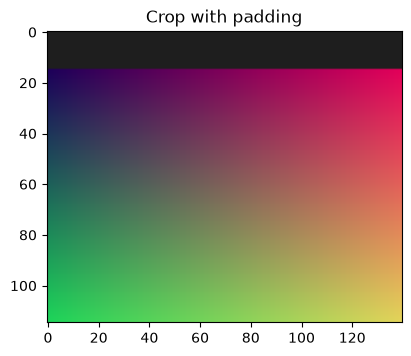

In [2]:
rows, columns = np.indices((120, 180))
pixels = np.stack((columns / 179, rows / 119, np.full(rows.shape, .35)), axis=-1)
image = ImageLand(pixels)

region = SquareMarks(-15, 100, 20, 160, shape=image.shape)
cropped = image.copy().zoom(region, save_trace=True, fill_color=(30, 30, 30))
cropped.show('Crop with padding')

### 2. Paste edited crop pixels back

Retracing a crop brings the edited pixels back onto the saved canvas. The surrounding pixels are retained. Fully transparent crop pixels leave the saved canvas intact. Undo a checkpoint instead when you want to discard every edit.

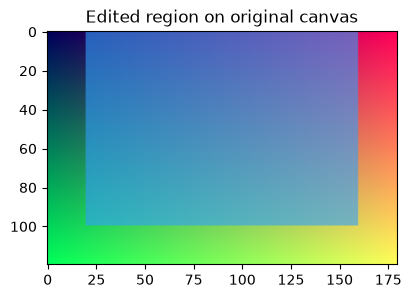

In [3]:
cropped.implant_filter(Filter('#30a0ff', .6)).retrace()
cropped.show('Edited region on original canvas')

### 3. Rectify a perspective region

QuadMarks orders a convex set of four corners clockwise starting at top-left. Image, heat and landmark zooms share the same projective matrix. A rotated SquareMarks must first become a QuadMarks.

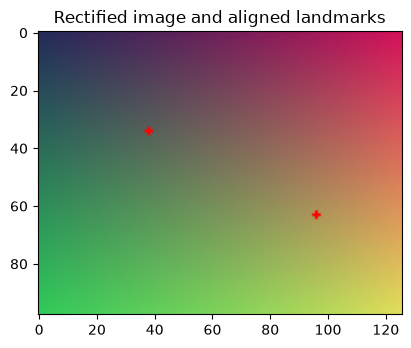

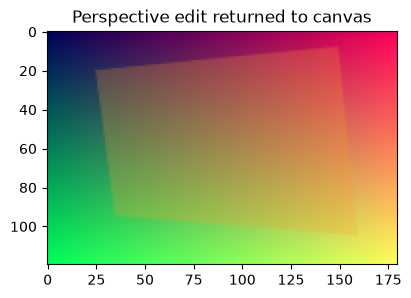

In [4]:
quad = QuadMarks((20, 25), (8, 150), (105, 160), (95, 35), shape=image.shape)
points = MarksLand([[45, 60], [70, 120]], shape=image.shape)
zoomed_image = image.copy().zoom(quad, save_trace=True)
zoomed_points = points.copy().zoom(quad, save_trace=True)
zoomed_heat = quad.to_heat().zoom(quad, save_trace=True)
(zoomed_image + zoomed_points).show('Rectified image and aligned landmarks')
zoomed_points.retrace()
zoomed_heat.retrace()
zoomed_image.implant_filter(Filter('#ffa030', .25)).retrace().show('Perspective edit returned to canvas')

## Checks

In [5]:
assert cropped.shape == image.shape
np.testing.assert_array_equal(cropped.get_image()[110:, :], image.get_image()[110:, :])
np.testing.assert_allclose(zoomed_points.get_marks(), points.get_marks(), atol=1e-10)
assert zoomed_heat.shape == image.shape
assert zoomed_image.shape == image.shape

## Next steps

Continue with tutorial 6 in the [tutorial index](https://github.com/bateni1380/landpy/tree/master/tutorials).